# **Genomic analysis of malaria vectors in The Gambia**

- In this notebook, based on the analyses of species and geographical population structure, we choose the appropriate group of samples from The Gambia and group them into cohorts for further analysis.

### **Genetic diversity**


- Further we compute genetic diversity summary statistics for the chosen cohorts.

- Then we investigate runs of homozygosity within the chosen cohorts.

In [ ]:
import os

In [ ]:
import os
import malariagen_data
import plotly.express as px
import pandas as pd

In [ ]:
ag3 = malariagen_data.Ag3(pre=True)
ag3

<MalariaGEN Ag3 API client>
Storage URL             : gs://vo_agam_release_master_us_central1
Data releases available : 3.0, 3.1, 3.10, 3.11, 3.12, 3.13, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9
Results cache           : None
Cohorts analysis        : 20240924
AIM analysis            : 20220528
Site filters analysis   : dt_20200416
Software version        : malariagen_data 13.5.0
Client location         : Iowa, United States (Google Cloud us-central1)
---
Please note that data are subject to terms of use,
for more information see https://www.malariagen.net/data
or contact support@malariagen.net. For API documentation see 
https://malariagen.github.io/malariagen-data-python/v13.5.0/Ag3.html

In [ ]:
gambia_sample_query = "country == 'Gambia, The' and sample_set == '1272-VO-GM-OPONDO-VMF00160'"

In [ ]:
# access metadata
df_samples_gambia = ag3.sample_metadata(sample_query=gambia_sample_query)
df_samples_gambia

,sample_id,partner_sample_id,contributor,country,location,year,month,latitude,longitude,sex_call,...,admin1_name,admin1_iso,admin2_name,taxon,cohort_admin1_year,cohort_admin1_month,cohort_admin1_quarter,cohort_admin2_year,cohort_admin2_month,cohort_admin2_quarter
0,VBS47721-6366STDY9854330,C1161,Kevin Opondo,"Gambia, The",Jareng,2019,9,13.620,-15.190,F,...,Janjanbureh,GM-M,Niamina East,coluzzii,GM-M_colu_2019,GM-M_colu_2019_09,GM-M_colu_2019_Q3,GM-M_Niamina-East_colu_2019,GM-M_Niamina-East_colu_2019_09,GM-M_Niamina-East_colu_2019_Q3
1,VBS47723-6366STDY9854332,C0454,Kevin Opondo,"Gambia, The",Dongoroba,2019,9,13.380,-15.294,F,...,Mansakonko,GM-L,Jarra East,arabiensis,GM-L_arab_2019,GM-L_arab_2019_09,GM-L_arab_2019_Q3,GM-L_Jarra-East_arab_2019,GM-L_Jarra-East_arab_2019_09,GM-L_Jarra-East_arab_2019_Q3
2,VBS47724-6366STDY9854333,C2526,Kevin Opondo,"Gambia, The",Bansang,2019,9,13.434,-14.655,F,...,Janjanbureh,GM-M,Upper Fuladu West,unassigned,NaN,NaN,NaN,NaN,NaN,NaN
3,VBS47725-6366STDY9854334,C2409,Kevin Opondo,"Gambia, The",Kerewan,2019,9,13.515,-14.896,F,...,Janjanbureh,GM-M,Lower Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Lower-Fuladu-West_arab_2019,GM-M_Lower-Fuladu-West_arab_2019_09,GM-M_Lower-Fuladu-West_arab_2019_Q3
4,VBS47726-6366STDY9854335,C0587,Kevin Opondo,"Gambia, The",Bansang,2019,9,13.434,-14.655,F,...,Janjanbureh,GM-M,Upper Fuladu West,arabiensis,GM-M_arab_2019,GM-M_arab_2019_09,GM-M_arab_2019_Q3,GM-M_Upper-Fuladu-West_arab_2019,GM-M_Upper-Fuladu-West_arab_2019_09,GM-M_Upper-Fuladu-West_arab_2019_Q3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
656,AG0312-C,I-14,Charles Godfray,"Gambia, The",Wali Kunda,2012,10,13.567,-14.917,F,...,Janjanbureh,GM-M,Lower Fuladu West,coluzzii,GM-M_colu_2012,GM-M_colu_2012_10,GM-M_colu_2012_Q4,GM-M_Lower-Fuladu-West_colu_2012,GM-M_Lower-Fuladu-West_colu_2012_10,GM-M_Lower-Fuladu-West_colu_2012_Q4
657,AG0316-C,I-18,Charles Godfray,"Gambia, The",Wali Kunda,2012,10,13.567,-14.917,F,...,Janjanbureh,GM-M,Lower Fuladu West,coluzzii,GM-M_colu_2012,GM-M_colu_2012_10,GM-M_colu_2012_Q4,GM-M_Lower-Fuladu-West_colu_2012,GM-M_Lower-Fuladu-West_colu_2012_10,GM-M_Lower-Fuladu-West_colu_2012_Q4
658,AG0303-C,O-504,Charles Godfray,"Gambia, The",Wali Kunda,2012,10,13.567,-14.917,F,...,Janjanbureh,GM-M,Lower Fuladu West,coluzzii,GM-M_colu_2012,GM-M_colu_2012_10,GM-M_colu_2012_Q4,GM-M_Lower-Fuladu-West_colu_2012,GM-M_Lower-Fuladu-West_colu_2012_10,GM-M_Lower-Fuladu-West_colu_2012_Q4
659,AG0301-C,O-494,Charles Godfray,"Gambia, The",Wali Kunda,2012,10,13.567,-14.917,F,...,Janjanbureh,GM-M,Lower Fuladu West,coluzzii,GM-M_colu_2012,GM-M_colu_2012_10,GM-M_colu_2012_Q4,GM-M_Lower-Fuladu-West_colu_2012,GM-M_Lower-Fuladu-West_colu_2012_10,GM-M_Lower-Fuladu-West_colu_2012_Q4


In [ ]:
gambia_df = ag3.count_samples(sample_query=gambia_sample_query)
gambia_df

taxon                                                      arabiensis  bissau  \
country     admin1_iso admin1_name admin2_name       year                       
Gambia, The GM-L       Mansakonko  Jarra East        2001           1       0   
                                                     2019           6       0   
                                   Kiang West        2006           0       0   
            GM-M       Janjanbureh Lower Fuladu West 2012           0       0   
                                                     2019          51       0   
                                   Niamina Dankunku  2019           0       1   
                                   Niamina East      2019          10       0   
                                   Niamina West      2019           8       0   
                                   Upper Fuladu West 2019          12       0   
                       Kuntaur     Niani             2019           4       0   
            GM-N       Kerewan     Central Badibu    2006           0       9   
                                                     2011           0      68   
                                   Illiasa           2006           0       0   
                                                     2019           3       0   
                                   Lower Niumi       2019          13       0   
            GM-U       Basse       Basse             2019          28       0   
                                   Jimara            2019          37       1   
                                   Sandu             2019           8       0   
                                   Tumana            2019          21       0   
                                   Wuli East         2019           1       0   
            GM-W       Brikama     Foni Brefet       2019           1       4   
                                   Kombo Central     2019          28       0   
                       Kanifing    Bakau             2019           6       0   
                                   Jeshwang          2019          77       0   

taxon                                                      coluzzii  gambiae  \
country     admin1_iso admin1_name admin2_name       year                      
Gambia, The GM-L       Mansakonko  Jarra East        2001         0        0   
                                                     2019         3        0   
                                   Kiang West        2006        19        0   
            GM-M       Janjanbureh Lower Fuladu West 2012       172        2   
                                                     2019        12        1   
                                   Niamina Dankunku  2019         0        0   
                                   Niamina East      2019         6        0   
                                   Niamina West      2019         1        2   
                                   Upper Fuladu West 2019         4        0   
                       Kuntaur     Niani             2019         4        0   
            GM-N       Kerewan     Central Badibu    2006         2        0   
                                                     2011         6        0   
                                   Illiasa           2006         1        0   
                                                     2019         0        0   
                                   Lower Niumi       2019         0        0   
            GM-U       Basse       Basse             2019         3        4   
                                   Jimara            2019         3       10   
                                   Sandu             2019         1        2   
                                   Tumana            2019         0        0   
                                   Wuli East         2019         0        0   
            GM-W       Brikama     Foni Brefet       2019         0        0   
                                   Kombo Central     

In [ ]:
df_samples_gambia.columns

Index(['sample_id', 'partner_sample_id', 'contributor', 'country', 'location',
       'year', 'month', 'latitude', 'longitude', 'sex_call', 'sample_set',
       'release', 'quarter', 'study_id', 'study_url',
       'terms_of_use_expiry_date', 'terms_of_use_url', 'unrestricted_use',
       'mean_cov', 'median_cov', 'modal_cov', 'mean_cov_2L', 'median_cov_2L',
       'mode_cov_2L', 'mean_cov_2R', 'median_cov_2R', 'mode_cov_2R',
       'mean_cov_3L', 'median_cov_3L', 'mode_cov_3L', 'mean_cov_3R',
       'median_cov_3R', 'mode_cov_3R', 'mean_cov_X', 'median_cov_X',
       'mode_cov_X', 'frac_gen_cov', 'divergence', 'contam_pct', 'contam_LLR',
       'aim_species_fraction_arab', 'aim_species_fraction_colu',
       'aim_species_fraction_colu_no2l', 'aim_species_gambcolu_arabiensis',
       'aim_species_gambiae_coluzzii', 'aim_species', 'country_iso',
       'admin1_name', 'admin1_iso', 'admin2_name', 'taxon',
       'cohort_admin1_year', 'cohort_admin1_month', 'cohort_admin1_quarter',
      

### **Choosing cohorts**

In [ ]:
df_samples_gambia.groupby("cohort_admin1_year").size()

cohort_admin1_year
GM-L_arab_2001      1
GM-L_arab_2019      6
GM-L_colu_2006     19
GM-L_colu_2019      3
GM-M_arab_2019     85
GM-M_biss_2019      1
GM-M_colu_2012    172
GM-M_colu_2019     27
GM-M_gamb_2012      2
GM-M_gamb_2019      3
GM-N_arab_2019     16
GM-N_biss_2006      9
GM-N_biss_2011     68
GM-N_colu_2006      3
GM-N_colu_2011      6
GM-U_arab_2019     95
GM-U_biss_2019      1
GM-U_colu_2019      7
GM-U_gamb_2019     16
GM-W_arab_2019    112
GM-W_biss_2019      4
dtype: int64

In [ ]:
df_samples_gambia.groupby("cohort_admin2_year").size()

cohort_admin2_year
GM-L_Jarra-East_arab_2001             1
GM-L_Jarra-East_arab_2019             6
GM-L_Jarra-East_colu_2019             3
GM-L_Kiang-West_colu_2006            19
GM-M_Lower-Fuladu-West_arab_2019     51
GM-M_Lower-Fuladu-West_colu_2012    172
GM-M_Lower-Fuladu-West_colu_2019     12
GM-M_Lower-Fuladu-West_gamb_2012      2
GM-M_Lower-Fuladu-West_gamb_2019      1
GM-M_Niamina-Dankunku_biss_2019       1
GM-M_Niamina-East_arab_2019          10
GM-M_Niamina-East_colu_2019           6
GM-M_Niamina-West_arab_2019           8
GM-M_Niamina-West_colu_2019           1
GM-M_Niamina-West_gamb_2019           2
GM-M_Niani_arab_2019                  4
GM-M_Niani_colu_2019                  4
GM-M_Upper-Fuladu-West_arab_2019     12
GM-M_Upper-Fuladu-West_colu_2019      4
GM-N_Central-Badibu_biss_2006         9
GM-N_Central-Badibu_biss_2011        68
GM-N_Central-Badibu_colu_2006         2
GM-N_Central-Badibu_colu_2011         6
GM-N_Illiasa_arab_2019                3
GM-N_Illiasa_colu_200

### **Genetic diversity in The Gambia samples**

In [ ]:
df_stats_admin2_gambia = ag3.diversity_stats(
    sample_query=gambia_sample_query,
    cohorts="admin2_year",
    cohort_size=10,
    region="3L:15,000,000-41,000,000",
    site_class="CDS_DEG_4",
    site_mask="gamb_colu_arab",
)

Cohort (GM-L_Jarra-East_arab_2001) has insufficient samples (1) for requested cohort size (10), dropping.
Cohort (GM-L_Jarra-East_arab_2019) has insufficient samples (6) for requested cohort size (10), dropping.
Cohort (GM-L_Jarra-East_colu_2019) has insufficient samples (3) for requested cohort size (10), dropping.
Cohort (GM-M_Lower-Fuladu-West_gamb_2012) has insufficient samples (2) for requested cohort size (10), dropping.
Cohort (GM-M_Lower-Fuladu-West_gamb_2019) has insufficient samples (1) for requested cohort size (10), dropping.
Cohort (GM-M_Niamina-Dankunku_biss_2019) has insufficient samples (1) for requested cohort size (10), dropping.
Cohort (GM-M_Niamina-East_colu_2019) has insufficient samples (6) for requested cohort size (10), dropping.
Cohort (GM-M_Niamina-West_arab_2019) has insufficient samples (8) for requested cohort size (10), dropping.
Cohort (GM-M_Niamina-West_colu_2019) has insufficient samples (1) for requested cohort size (10), dropping.
Cohort (GM-M_Niamina

In [ ]:
df_stats_admin2_gambia

,cohort,theta_pi,theta_pi_estimate,theta_pi_bias,theta_pi_std_err,theta_pi_ci_err,theta_pi_ci_low,theta_pi_ci_upp,theta_w,theta_w_estimate,...,tajima_d_ci_upp,taxon,year,month,country,admin1_iso,admin1_name,admin2_name,longitude,latitude
0,GM-L_Kiang-West_colu_2006,0.022726,0.022730,-4.370197e-06,0.000313,0.001229,0.022116,0.023345,0.032843,0.032845,...,-1.263266,coluzzii,2006,8,"Gambia, The",GM-L,Mansakonko,Kiang West,-16.033000,13.417000
1,GM-M_Lower-Fuladu-West_arab_2019,0.014193,0.014193,2.238102e-08,0.000232,0.000909,0.013739,0.014648,0.019449,0.019448,...,-1.089994,arabiensis,2019,"[9, 10, 11]","Gambia, The",GM-M,Janjanbureh,Lower Fuladu West,-14.902039,13.530882
2,GM-M_Lower-Fuladu-West_colu_2012,0.022212,0.022212,6.452191e-09,0.000320,0.001255,0.021584,0.022839,0.031531,0.031527,...,-1.208773,coluzzii,2012,10,"Gambia, The",GM-M,Janjanbureh,Lower Fuladu West,-14.917000,13.567000
3,GM-M_Lower-Fuladu-West_colu_2019,0.022413,0.022417,-4.377212e-06,0.000315,0.001236,0.021799,0.023035,0.031741,0.031745,...,-1.201647,coluzzii,2019,9,"Gambia, The",GM-M,Janjanbureh,Lower Fuladu West,-14.910500,13.542333
4,GM-M_Niamina-East_arab_2019,0.014482,0.014480,2.125570e-06,0.000231,0.000904,0.014028,0.014932,0.020270,0.020263,...,-1.157986,arabiensis,2019,"[9, 12]","Gambia, The",GM-M,Janjanbureh,Niamina East,-15.157000,13.619500
5,GM-M_Upper-Fuladu-West_arab_2019,0.013595,0.013594,3.480166e-07,0.000232,0.000908,0.013140,0.014048,0.017793,0.017795,...,-0.945120,arabiensis,2019,9,"Gambia, The",GM-M,Janjanbureh,Upper Fuladu West,-14.655000,13.434000
6,GM-N_Central-Badibu_biss_2011,0.022041,0.022043,-2.227819e-06,0.000318,0.001245,0.021420,0.022665,0.029828,0.029826,...,-1.062495,bissau,2011,"[8, 9, 10]","Gambia, The",GM-N,Kerewan,Central Badibu,-15.900000,13.550000
7,GM-N_Lower-Niumi_arab_2019,0.013401,0.013400,1.199394e-06,0.000233,0.000912,0.012944,0.013856,0.016860,0.016857,...,-0.815360,arabiensis,2019,10,"Gambia, The",GM-N,Kerewan,Lower Niumi,-16.515000,13.481000
8,GM-U_Basse_arab_2019,0.013572,0.013571,3.223275e-07,0.000231,0.000907,0.013118,0.014025,0.017847,0.017847,...,-0.961326,arabiensis,2019,9,"Gambia, The",GM-U,Basse,Basse,-14.205750,13.269286
9,GM-U_Jimara_arab_2019,0.013483,0.013481,1.644813e-06,0.000237,0.000931,0.013016,0.013947,0.017672,0.017669,...,-0.951968,arabiensis,2019,"[9, 10]","Gambia, The",GM-U,Basse,Jimara,-14.324162,13.275973


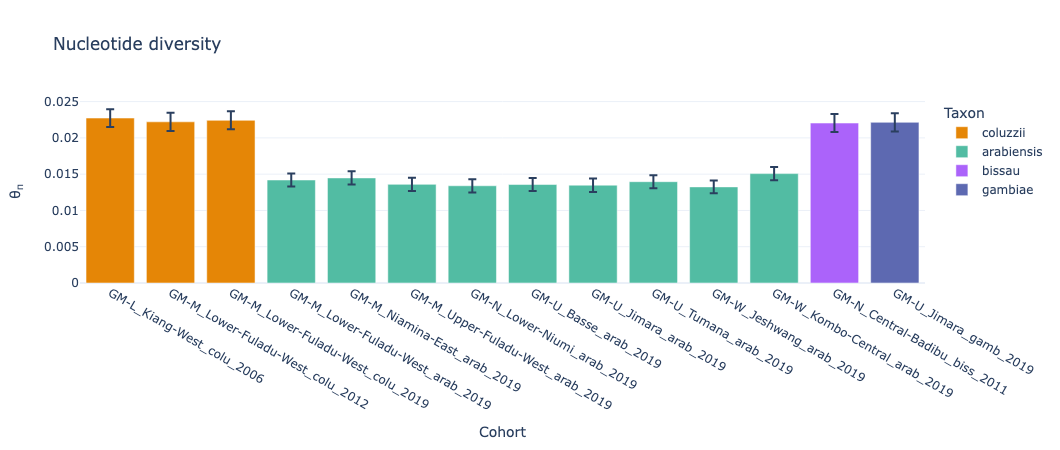

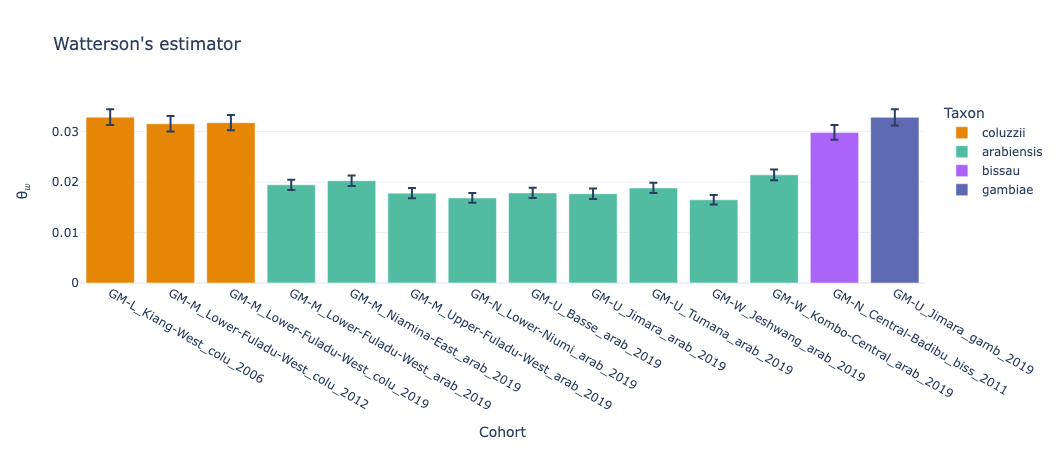

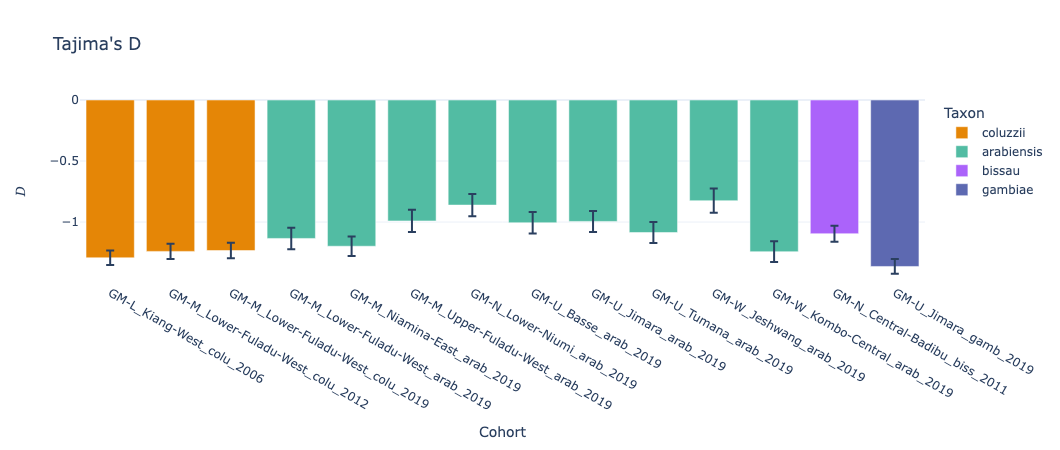

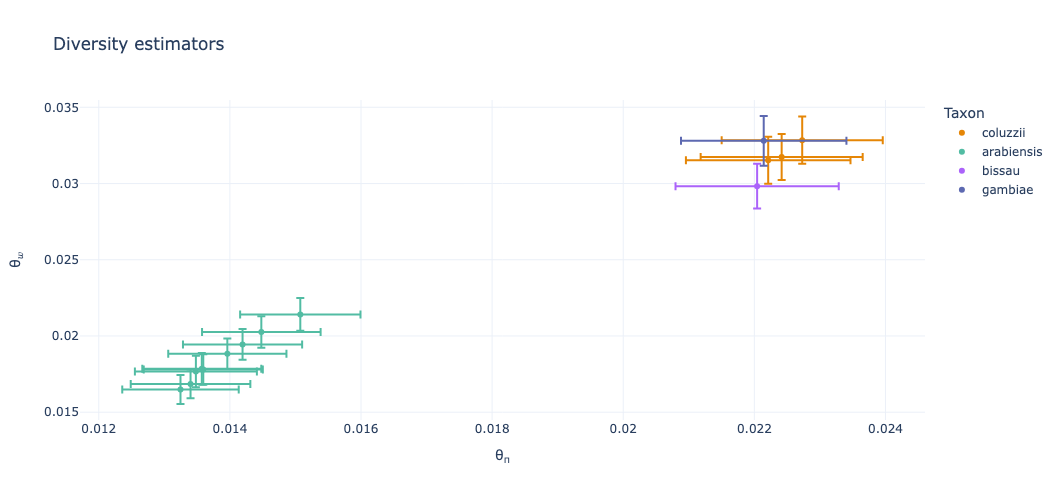

In [ ]:
ag3.plot_diversity_stats(df_stats_admin2_gambia, color="taxon")

#### **Genetic diversity in _An. arabiensis_**

- set order and index

In [ ]:
arab_region = (
    df_samples_gambia
    .pivot_table(
        index={"admin1_name", "admin2_name"},
        columns="taxon",
        values="sample_id",
        aggfunc="count",
        fill_value=0
    )
)
arab_region

,taxon,arabiensis,bissau,coluzzii,gambiae,unassigned
admin2_name,admin1_name,,,,,
Bakau,Kanifing,6,0,0,0,0
Basse,Basse,28,0,3,4,1
Central Badibu,Kerewan,0,77,8,0,0
Foni Brefet,Brikama,1,4,0,0,0
Illiasa,Kerewan,3,0,1,0,0
Jarra East,Mansakonko,7,0,3,0,0
Jeshwang,Kanifing,77,0,0,0,0
Jimara,Basse,37,1,3,10,1
Kiang West,Mansakonko,0,0,19,0,0


In [ ]:
# order regions from west to east (aka coastal to inland regions)

df_gambia_regions = (
    df_samples_gambia
    .groupby("admin1_name")
    .aggregate({
        "longitude": "mean"})
    .sort_values("longitude")
)
df_gambia_regions

,longitude
admin1_name,
Kanifing,-16.671205
Brikama,-16.620182
Kerewan,-15.966725
Mansakonko,-15.778172
Janjanbureh,-14.927292
Kuntaur,-14.919250
Basse,-14.235074


In [ ]:
df_gambia_admin2 = (
    df_samples_gambia
    .groupby("admin2_name")
    .aggregate({
        "longitude": "mean"})
    .sort_values("longitude")
)
df_gambia_admin2

,longitude
admin2_name,
Bakau,-16.674000
Jeshwang,-16.670987
Kombo Central,-16.657000
Lower Niumi,-16.515000
Foni Brefet,-16.414000
Kiang West,-16.033000
Central Badibu,-15.900000
Illiasa,-15.602750
Jarra East,-15.294000


In [ ]:
gambia_admin2 = df_gambia_admin2.index.tolist()
gambia_admin2

['Bakau',
 'Jeshwang',
 'Kombo Central',
 'Lower Niumi',
 'Foni Brefet',
 'Kiang West',
 'Central Badibu',
 'Illiasa',
 'Jarra East',
 'Niamina Dankunku',
 'Niamina West',
 'Niamina East',
 'Niani',
 'Lower Fuladu West',
 'Upper Fuladu West',
 'Jimara',
 'Sandu',
 'Basse',
 'Tumana',
 'Wuli East']

In [ ]:
df_stats_admin2_arab = (
    df_stats_admin2_gambia
    .query("taxon == 'arabiensis'")
    .sort_values("longitude")
    .reset_index()
)
df_stats_admin2_arab

,index,cohort,theta_pi,theta_pi_estimate,theta_pi_bias,theta_pi_std_err,theta_pi_ci_err,theta_pi_ci_low,theta_pi_ci_upp,theta_w,...,tajima_d_ci_upp,taxon,year,month,country,admin1_iso,admin1_name,admin2_name,longitude,latitude
0,12,GM-W_Jeshwang_arab_2019,0.013248,0.013247,1.768183e-06,0.000227,0.000888,0.012802,0.013691,0.016488,...,-0.775591,arabiensis,2019,9,"Gambia, The",GM-W,Kanifing,Jeshwang,-16.670987,13.437247
1,13,GM-W_Kombo-Central_arab_2019,0.015076,0.015074,1.466039e-06,0.000234,0.000918,0.014615,0.015533,0.021418,...,-1.200445,arabiensis,2019,9,"Gambia, The",GM-W,Brikama,Kombo Central,-16.657000,13.290000
2,7,GM-N_Lower-Niumi_arab_2019,0.013401,0.013400,1.199394e-06,0.000233,0.000912,0.012944,0.013856,0.016860,...,-0.815360,arabiensis,2019,10,"Gambia, The",GM-N,Kerewan,Lower Niumi,-16.515000,13.481000
3,4,GM-M_Niamina-East_arab_2019,0.014482,0.014480,2.125570e-06,0.000231,0.000904,0.014028,0.014932,0.020270,...,-1.157986,arabiensis,2019,"[9, 12]","Gambia, The",GM-M,Janjanbureh,Niamina East,-15.157000,13.619500
4,1,GM-M_Lower-Fuladu-West_arab_2019,0.014193,0.014193,2.238102e-08,0.000232,0.000909,0.013739,0.014648,0.019449,...,-1.089994,arabiensis,2019,"[9, 10, 11]","Gambia, The",GM-M,Janjanbureh,Lower Fuladu West,-14.902039,13.530882
5,5,GM-M_Upper-Fuladu-West_arab_2019,0.013595,0.013594,3.480166e-07,0.000232,0.000908,0.013140,0.014048,0.017793,...,-0.945120,arabiensis,2019,9,"Gambia, The",GM-M,Janjanbureh,Upper Fuladu West,-14.655000,13.434000
6,9,GM-U_Jimara_arab_2019,0.013483,0.013481,1.644813e-06,0.000237,0.000931,0.013016,0.013947,0.017672,...,-0.951968,arabiensis,2019,"[9, 10]","Gambia, The",GM-U,Basse,Jimara,-14.324162,13.275973
7,8,GM-U_Basse_arab_2019,0.013572,0.013571,3.223275e-07,0.000231,0.000907,0.013118,0.014025,0.017847,...,-0.961326,arabiensis,2019,9,"Gambia, The",GM-U,Basse,Basse,-14.205750,13.269286
8,11,GM-U_Tumana_arab_2019,0.013965,0.013961,3.530969e-06,0.000230,0.000902,0.013511,0.014412,0.018837,...,-1.042728,arabiensis,2019,"[10, 11, 12]","Gambia, The",GM-U,Basse,Tumana,-14.049190,13.355952


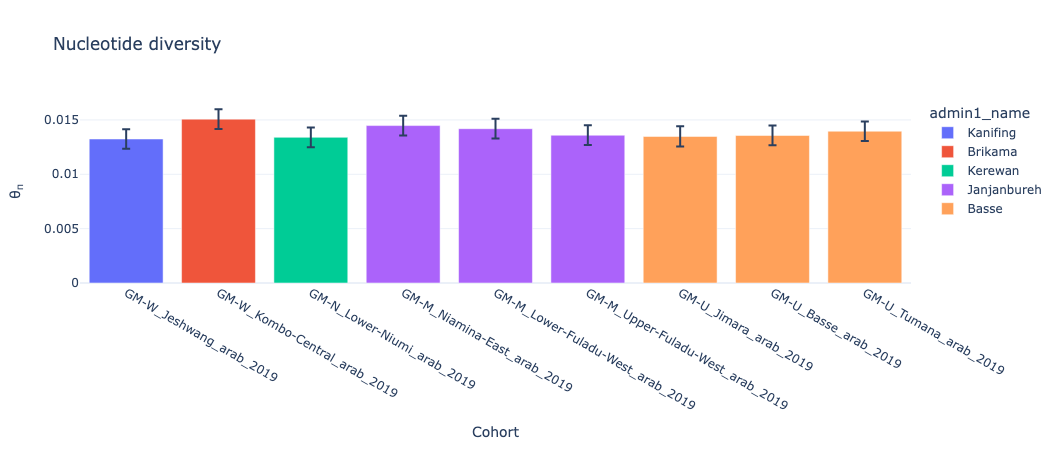

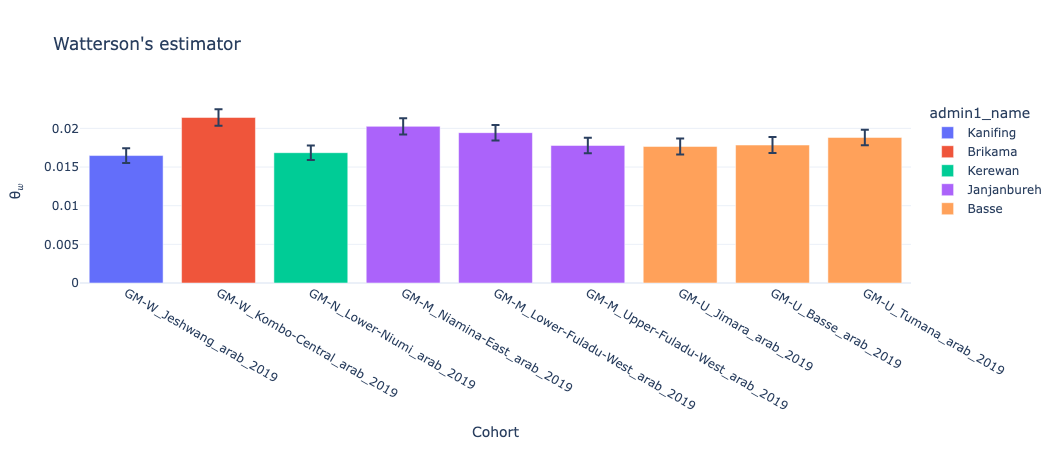

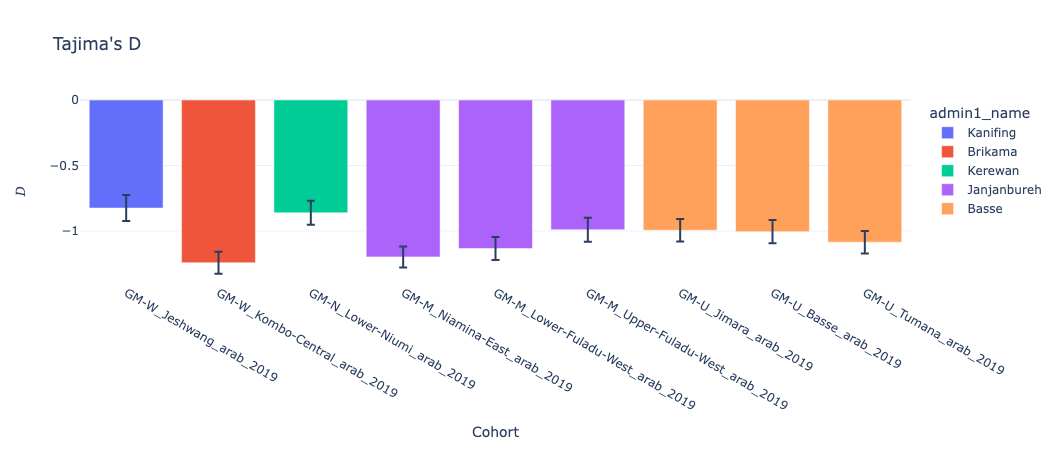

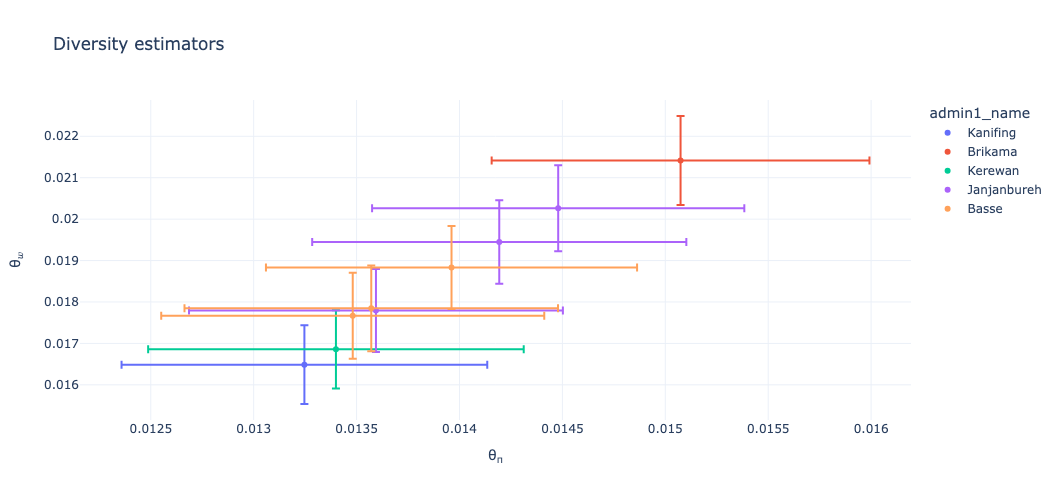

In [ ]:
ag3.plot_diversity_stats(df_stats_admin2_arab, color="admin1_name")

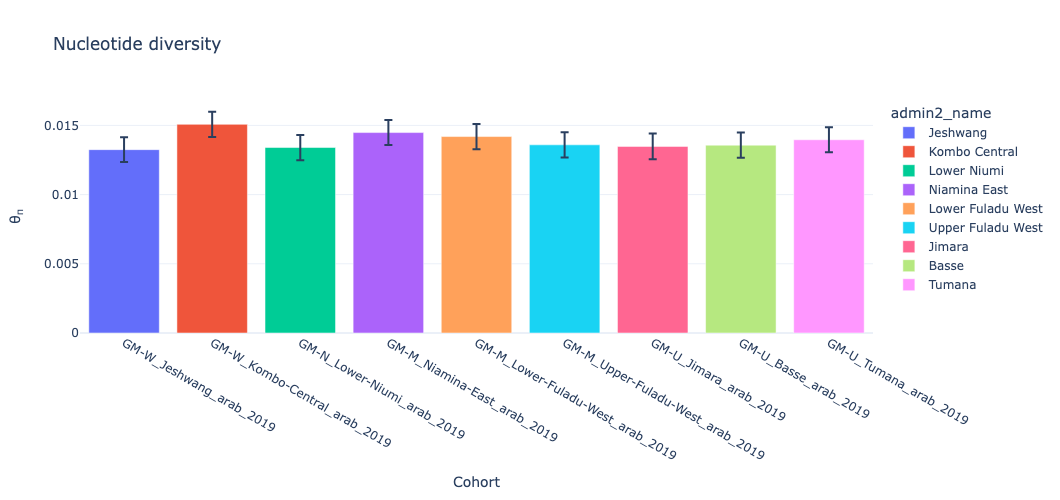

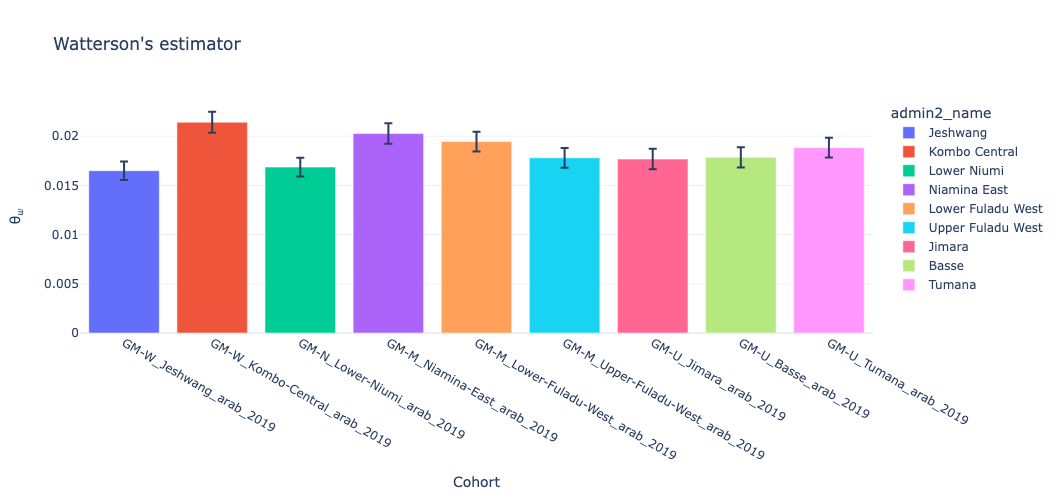

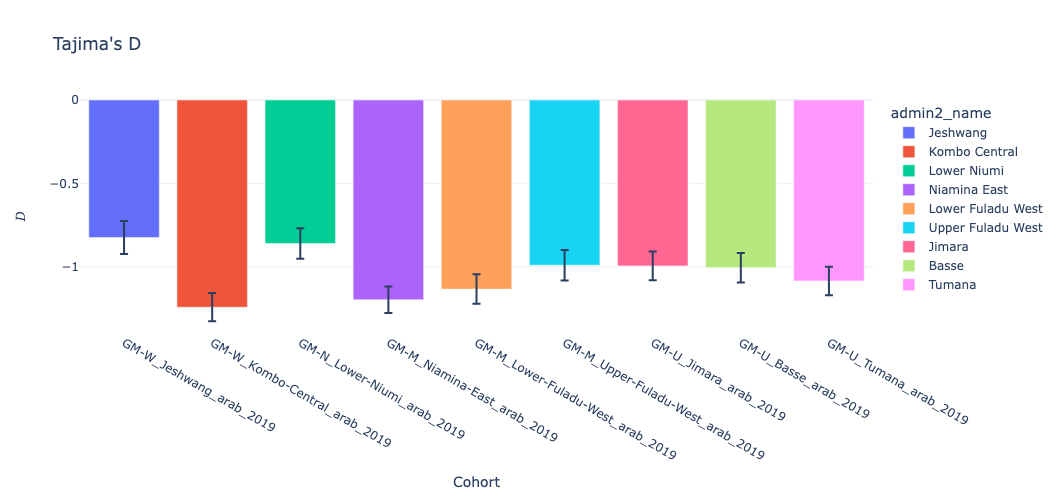

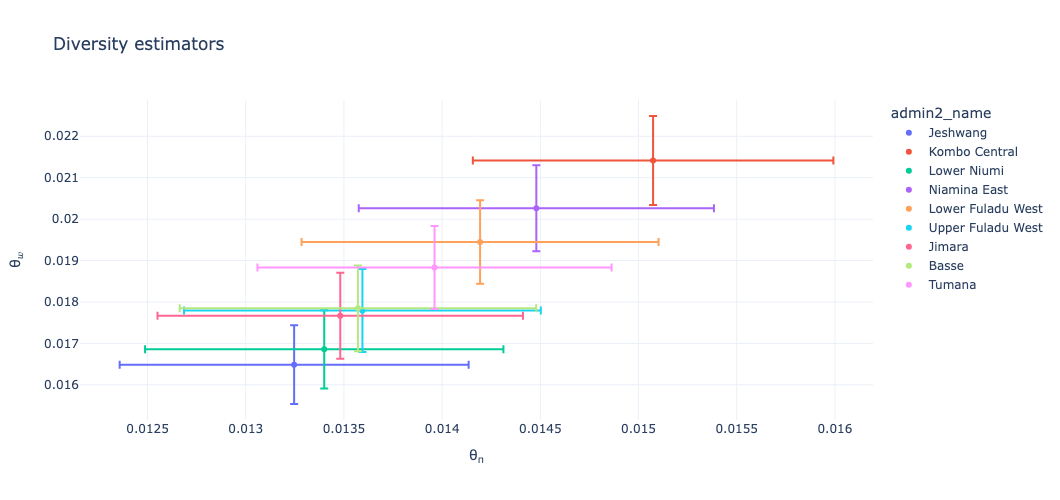

In [ ]:
ag3.plot_diversity_stats(df_stats_admin2_arab, color="admin2_name", bar_plot_height=500, scatter_plot_height=500)

In [ ]:
# color mappings

color_mapping_admin1 = {
    'Mansakonko': '#ffd966',
    'Janjanbureh': '#f4a261',
    'Kuntaur': '#2ca25f',
    'Basse': '#99d8c9',
    'Kanifing': '#a6bddb',
    'Brikama': '#d2c4e6',
    'Kerewan': '#2b8cbe'
}

color_mapping_admin2 = {
    'Jarra East': '#8e8c84',
    'Lower Fuladu West': '#7f7f7f',
    'Upper Fuladu West': '#6b705c',
    'Niani': '#4a4e4d',
    'Niamina East': '#3b5c40',
    'Jimara': '#8e7d32',
    'Basse': '#a95b29',
    'Wuli East': '#b64d3b',
    'Tumana': '#8a4b39',
    'Niamina West': '#6f4e37',
    'Sandu': '#3e3a3a',
    'Jeshwang': '#a4c9e2',
    'Kombo Central': '#78aaff',
    'Lower Niumi': '#4d88ff',
    'Bakau': '#0077b6',
    'Illiasa': '#0096c7',
    'Foni Brefet': '#00b4d8'
}

In [ ]:
df = pd.DataFrame(df_stats_admin2_arab)
df

,index,cohort,theta_pi,theta_pi_estimate,theta_pi_bias,theta_pi_std_err,theta_pi_ci_err,theta_pi_ci_low,theta_pi_ci_upp,theta_w,...,tajima_d_ci_upp,taxon,year,month,country,admin1_iso,admin1_name,admin2_name,longitude,latitude
0,12,GM-W_Jeshwang_arab_2019,0.013248,0.013247,1.768183e-06,0.000227,0.000888,0.012802,0.013691,0.016488,...,-0.775591,arabiensis,2019,9,"Gambia, The",GM-W,Kanifing,Jeshwang,-16.670987,13.437247
1,13,GM-W_Kombo-Central_arab_2019,0.015076,0.015074,1.466039e-06,0.000234,0.000918,0.014615,0.015533,0.021418,...,-1.200445,arabiensis,2019,9,"Gambia, The",GM-W,Brikama,Kombo Central,-16.657000,13.290000
2,7,GM-N_Lower-Niumi_arab_2019,0.013401,0.013400,1.199394e-06,0.000233,0.000912,0.012944,0.013856,0.016860,...,-0.815360,arabiensis,2019,10,"Gambia, The",GM-N,Kerewan,Lower Niumi,-16.515000,13.481000
3,4,GM-M_Niamina-East_arab_2019,0.014482,0.014480,2.125570e-06,0.000231,0.000904,0.014028,0.014932,0.020270,...,-1.157986,arabiensis,2019,"[9, 12]","Gambia, The",GM-M,Janjanbureh,Niamina East,-15.157000,13.619500
4,1,GM-M_Lower-Fuladu-West_arab_2019,0.014193,0.014193,2.238102e-08,0.000232,0.000909,0.013739,0.014648,0.019449,...,-1.089994,arabiensis,2019,"[9, 10, 11]","Gambia, The",GM-M,Janjanbureh,Lower Fuladu West,-14.902039,13.530882
5,5,GM-M_Upper-Fuladu-West_arab_2019,0.013595,0.013594,3.480166e-07,0.000232,0.000908,0.013140,0.014048,0.017793,...,-0.945120,arabiensis,2019,9,"Gambia, The",GM-M,Janjanbureh,Upper Fuladu West,-14.655000,13.434000
6,9,GM-U_Jimara_arab_2019,0.013483,0.013481,1.644813e-06,0.000237,0.000931,0.013016,0.013947,0.017672,...,-0.951968,arabiensis,2019,"[9, 10]","Gambia, The",GM-U,Basse,Jimara,-14.324162,13.275973
7,8,GM-U_Basse_arab_2019,0.013572,0.013571,3.223275e-07,0.000231,0.000907,0.013118,0.014025,0.017847,...,-0.961326,arabiensis,2019,9,"Gambia, The",GM-U,Basse,Basse,-14.205750,13.269286
8,11,GM-U_Tumana_arab_2019,0.013965,0.013961,3.530969e-06,0.000230,0.000902,0.013511,0.014412,0.018837,...,-1.042728,arabiensis,2019,"[10, 11, 12]","Gambia, The",GM-U,Basse,Tumana,-14.049190,13.355952


In [ ]:
# Apply color mapping
df['color_admin2'] = df['admin2_name'].map(color_mapping_admin2)
df

,index,cohort,theta_pi,theta_pi_estimate,theta_pi_bias,theta_pi_std_err,theta_pi_ci_err,theta_pi_ci_low,theta_pi_ci_upp,theta_w,...,taxon,year,month,country,admin1_iso,admin1_name,admin2_name,longitude,latitude,color_admin2
0,12,GM-W_Jeshwang_arab_2019,0.013248,0.013247,1.768183e-06,0.000227,0.000888,0.012802,0.013691,0.016488,...,arabiensis,2019,9,"Gambia, The",GM-W,Kanifing,Jeshwang,-16.670987,13.437247,#a4c9e2
1,13,GM-W_Kombo-Central_arab_2019,0.015076,0.015074,1.466039e-06,0.000234,0.000918,0.014615,0.015533,0.021418,...,arabiensis,2019,9,"Gambia, The",GM-W,Brikama,Kombo Central,-16.657000,13.290000,#78aaff
2,7,GM-N_Lower-Niumi_arab_2019,0.013401,0.013400,1.199394e-06,0.000233,0.000912,0.012944,0.013856,0.016860,...,arabiensis,2019,10,"Gambia, The",GM-N,Kerewan,Lower Niumi,-16.515000,13.481000,#4d88ff
3,4,GM-M_Niamina-East_arab_2019,0.014482,0.014480,2.125570e-06,0.000231,0.000904,0.014028,0.014932,0.020270,...,arabiensis,2019,"[9, 12]","Gambia, The",GM-M,Janjanbureh,Niamina East,-15.157000,13.619500,#3b5c40
4,1,GM-M_Lower-Fuladu-West_arab_2019,0.014193,0.014193,2.238102e-08,0.000232,0.000909,0.013739,0.014648,0.019449,...,arabiensis,2019,"[9, 10, 11]","Gambia, The",GM-M,Janjanbureh,Lower Fuladu West,-14.902039,13.530882,#7f7f7f
5,5,GM-M_Upper-Fuladu-West_arab_2019,0.013595,0.013594,3.480166e-07,0.000232,0.000908,0.013140,0.014048,0.017793,...,arabiensis,2019,9,"Gambia, The",GM-M,Janjanbureh,Upper Fuladu West,-14.655000,13.434000,#6b705c
6,9,GM-U_Jimara_arab_2019,0.013483,0.013481,1.644813e-06,0.000237,0.000931,0.013016,0.013947,0.017672,...,arabiensis,2019,"[9, 10]","Gambia, The",GM-U,Basse,Jimara,-14.324162,13.275973,#8e7d32
7,8,GM-U_Basse_arab_2019,0.013572,0.013571,3.223275e-07,0.000231,0.000907,0.013118,0.014025,0.017847,...,arabiensis,2019,9,"Gambia, The",GM-U,Basse,Basse,-14.205750,13.269286,#a95b29
8,11,GM-U_Tumana_arab_2019,0.013965,0.013961,3.530969e-06,0.000230,0.000902,0.013511,0.014412,0.018837,...,arabiensis,2019,"[10, 11, 12]","Gambia, The",GM-U,Basse,Tumana,-14.049190,13.355952,#8a4b39


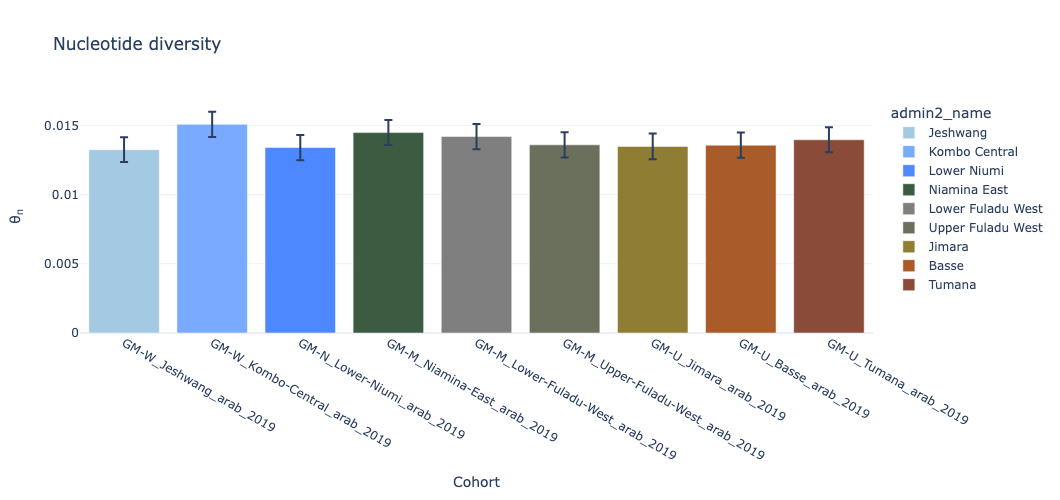

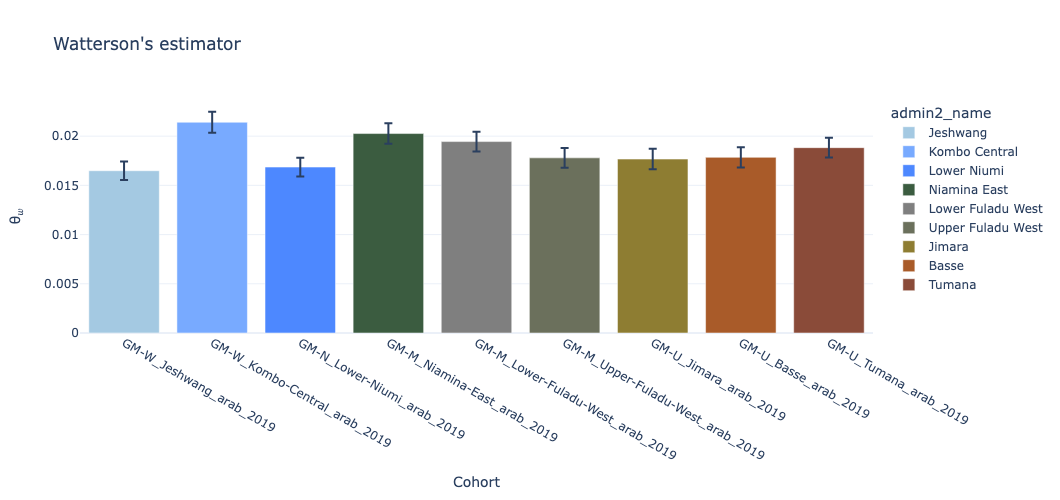

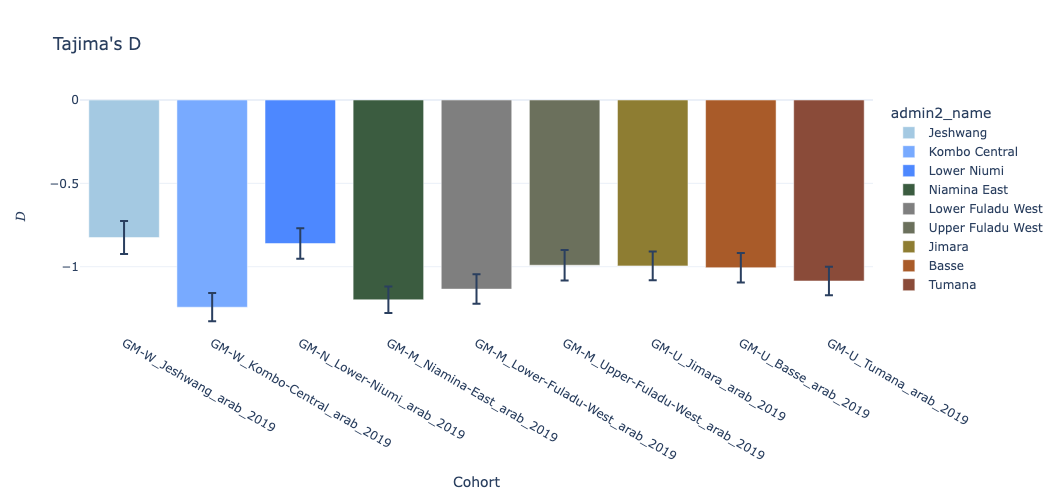

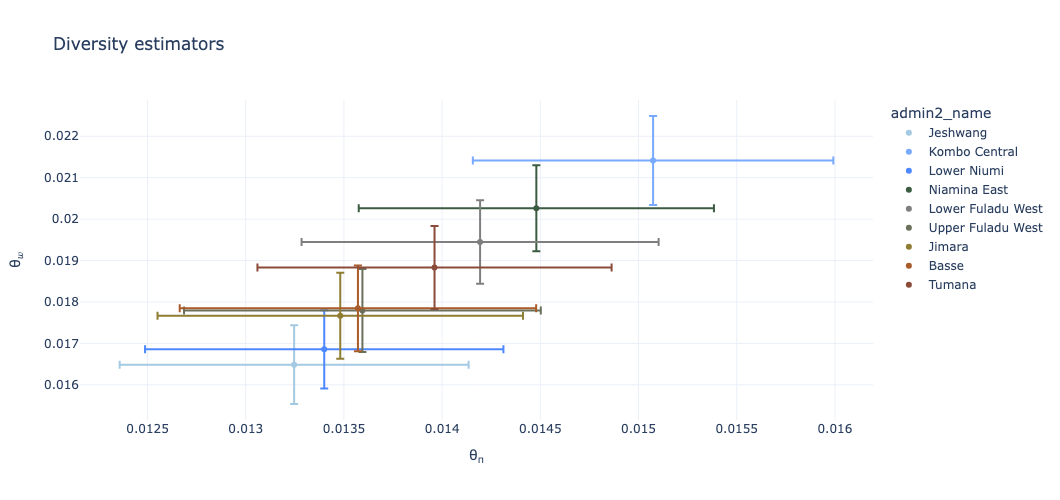

In [ ]:
ag3.plot_diversity_stats(df, color="admin2_name", color_discrete_map=color_mapping_admin2, bar_plot_height=500, scatter_plot_height=500)